# **Lab 7(A) - Laplacian Filter**

In [ ]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)




## Apply Laplacian Filter on Image to get Sharp Image

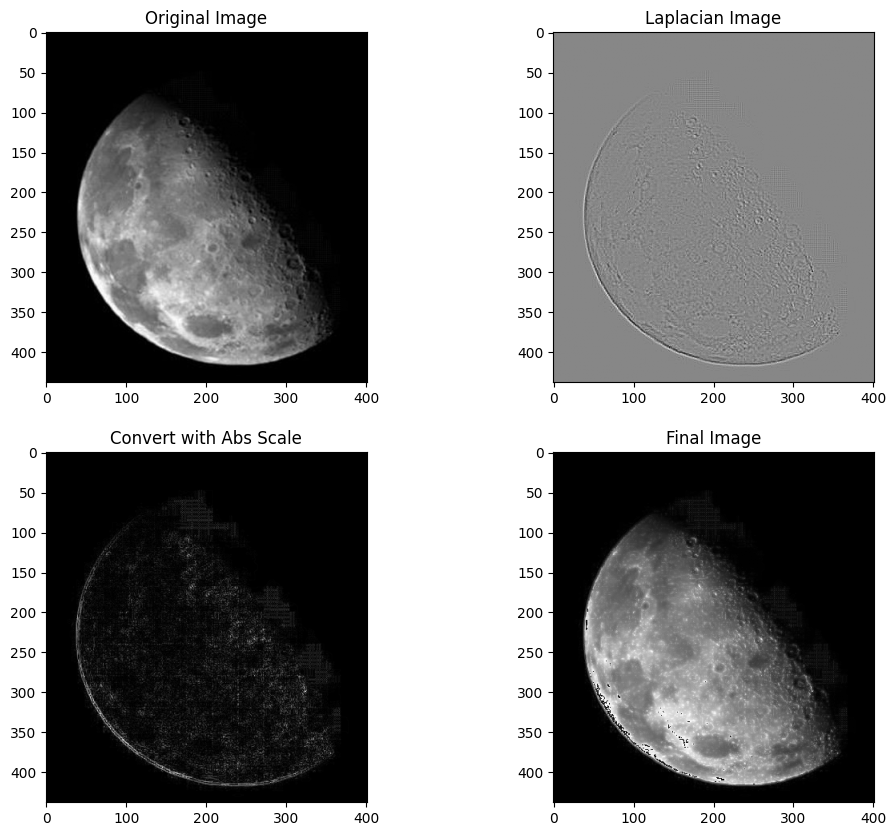

In [ ]:

# ================ ( Laplacian Filter ) ===================


# 0. Image file path
imgFile = "moon.jpg"

# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Manually define the Laplacian Kernel
# This is the standard 3x3 kernel that detects horizontal and vertical edges
manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

# Alternative kernel: Detects diagonal edges as well
# manual_kernel = np.array([
#     [1,  1,  1],
#     [1, -8,  1],
#     [1,  1,  1]
# ], dtype=np.float32)

# 3. Apply the filter using filter2D
# -1 indicates the output image will have the same depth as the source
# However, for Laplacian, use cv2.CV_64F to avoid clipping negative values
laplacian_manual = cv2.filter2D(img, cv2.CV_64F, manual_kernel)

# 4. Take absolute value and convert back to 8-bit (0-255)
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)

finalImage = img + laplacian_abs

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian_manual, cmap='gray'), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_abs, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage, cmap='gray'), plt.title('Final Image')
plt.show()


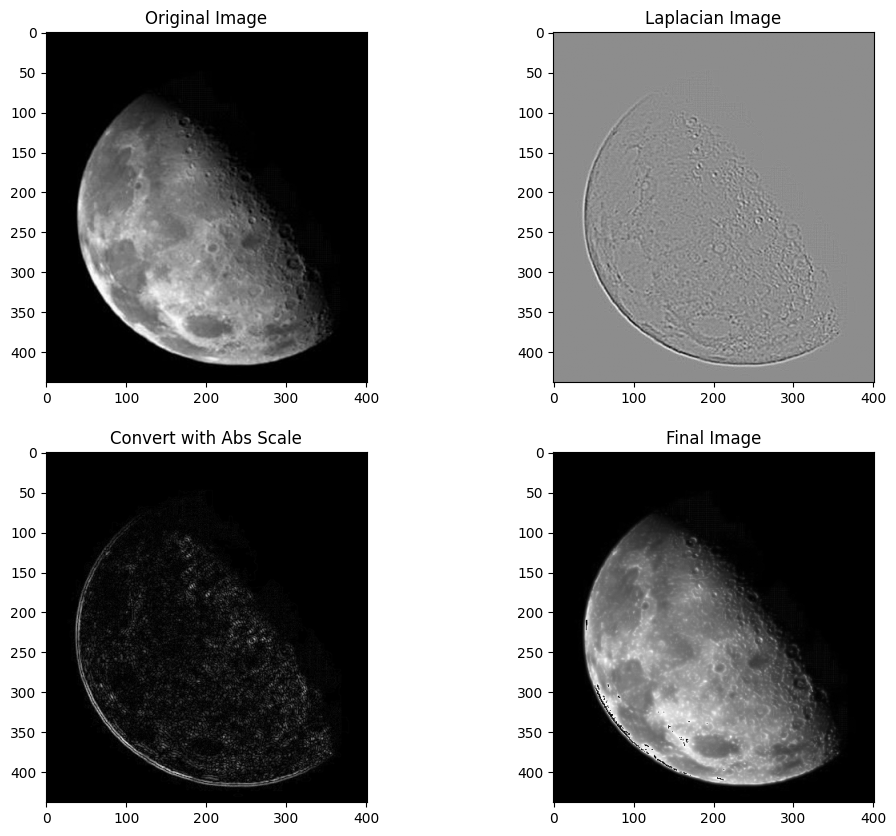

In [ ]:
# ================== ( Laplacian Filter ) ===============

# 1. Optional: Apply Gaussian Blur to reduce noise
# This prevents the algorithm from picking up tiny details as edges
blurred = cv2.GaussianBlur(img, (3, 3), 0)

# 2. Apply the Laplacian Algorithm
# Use CV_64F to capture both positive and negative gradients (essential for edges)
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)

# 3. Convert back to 8-bit image to view it properly
laplacian_8bit = cv2.convertScaleAbs(laplacian)

# 4. Adding Laplace and origianl Image
finalImage2 = img + laplacian_8bit

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian, cmap='gray'), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_8bit, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage2, cmap='gray'), plt.title('Final Image')
plt.show()




## Evaluating the Laplacian Filter on Noisy Images

Laplacian filters are second-order derivative filters, making them extremely sensitive to high-frequency noise (like Gaussian noise or Salt & Pepper noise). Let's see how our Laplacian edge detector performs on `noise.jpg` and `salt&Pepper.jpg` with and without Gaussian blurring.

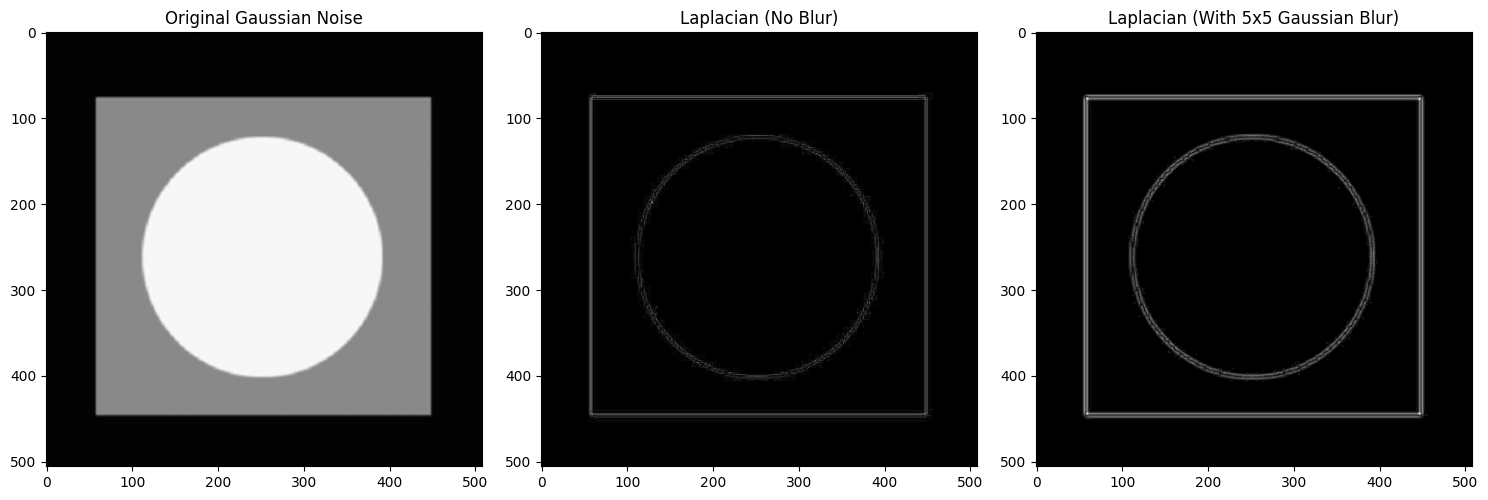

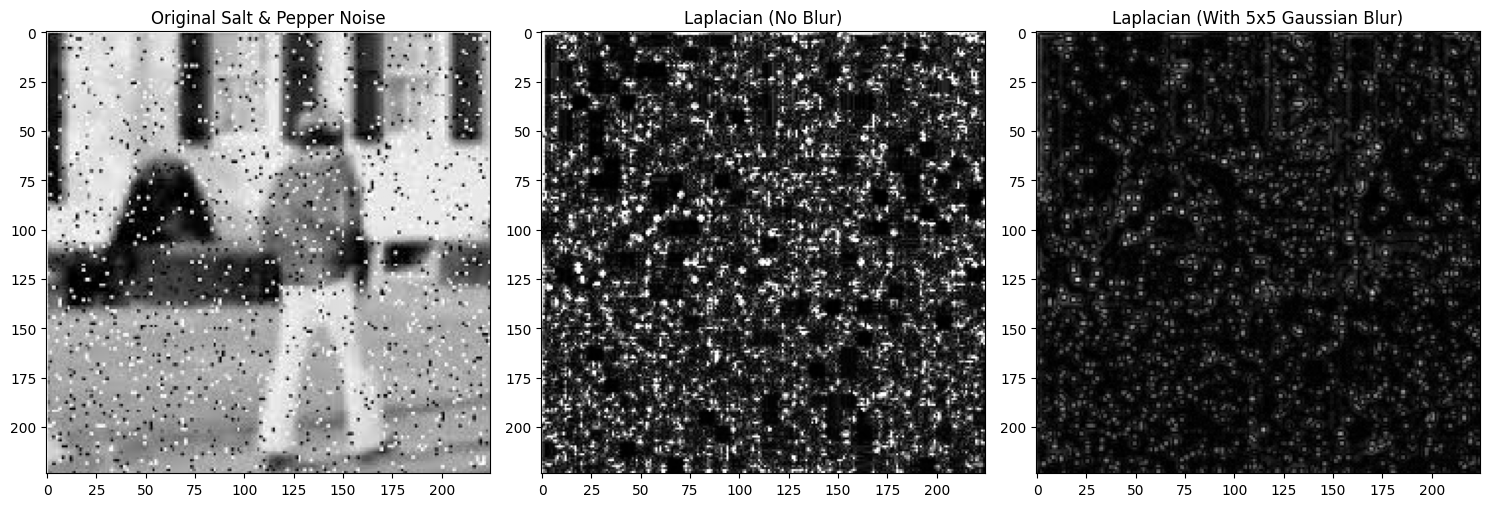

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the noisy images in grayscale
img_noise = cv2.imread('noise.jpg', 0)
img_salt_pepper = cv2.imread('salt&Pepper.jpg', 0)

def process_and_plot(image, title):
    if image is None:
        print(f"Error: Could not load {title} image.")
        return

    # 1. Direct Laplacian (No blur)
    laplacian_direct = cv2.Laplacian(image, cv2.CV_64F)
    laplacian_direct_abs = cv2.convertScaleAbs(laplacian_direct)

    # 2. Laplacian with Gaussian Blur preprocessing
    blurred = cv2.GaussianBlur(image, (5, 5), 0)
    laplacian_blurred = cv2.Laplacian(blurred, cv2.CV_64F)
    laplacian_blurred_abs = cv2.convertScaleAbs(laplacian_blurred)

    # Display results
    plt.figure(figsize=(15, 5))
    plt.subplot(131), plt.imshow(image, cmap='gray'), plt.title(f'Original {title}')
    plt.subplot(132), plt.imshow(laplacian_direct_abs, cmap='gray'), plt.title('Laplacian (No Blur)')
    plt.subplot(133), plt.imshow(laplacian_blurred_abs, cmap='gray'), plt.title('Laplacian (With 5x5 Gaussian Blur)')
    plt.tight_layout()
    plt.show()

# Process both images
process_and_plot(img_noise, 'Gaussian Noise')
process_and_plot(img_salt_pepper, 'Salt & Pepper Noise')

## Inspecting the Second Lab Notebook: Maths & Statistics Filters

In [2]:
import json

# Path to the second notebook
notebook_path = '/content/Lab_7_(B)_Maths_&_Statistics_Filters.ipynb'

try:
    with open(notebook_path, 'r', encoding='utf-8') as f:
        nb_data = json.load(f)

    # Display the structure of the target notebook
    print(f"Notebook: {notebook_path}")
    print(f"Number of cells: {len(nb_data['cells'])}\n")

    for idx, cell in enumerate(nb_data['cells']):
        cell_type = cell.get('cell_type', 'unknown')
        source = "".join(cell.get('source', []))
        # Print a preview of each cell
        preview = source[:200] + '...' if len(source) > 200 else source
        print(f"--- Cell {idx} ({cell_type}) ---")
        print(preview)
        print("\n")
except Exception as e:
    print(f"Error reading notebook: {e}")

Notebook: /content/Lab_7_(B)_Maths_&_Statistics_Filters.ipynb
Number of cells: 19

--- Cell 0 (markdown) ---
# **Lab 7(B) - Mathematical and Statistical Filters**


--- Cell 1 (code) ---
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)


--- Cell 2 (code) ---
# ========== ( Adding nosie to an Image ) =================

# 0. Read an Image
imgPath = 'noise.jpg'
img = cv2.imread(imgPath, 0)

# 1. Function that handle all noise algorithm (Guassian, Exp, Unifor...


--- Cell 3 (code) ---
# --- METHOD 1: Using Built-in OpenCV function ---

# 2. Apply Arithmetic Mean Filter (using a 5x5 blur window)
# The larger the numbers in (3, 3), the smoother the image becomes.,
# you can change ke...


--- Cell 4 (code) ---



--- Cell 5 (code) ---
# --- METHOD 2: Manual implementation using a Kernel ---

# An Arithmetic Mean kernel is just a matrix of 1s divided by the total number of pixels.
kernel_size = 3
ker

# **Lab 7(B) - Mathematical and Statistical Filters**

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the noisy images in grayscale
img_noise = cv2.imread('noise.jpg', 0)
img_salt_pepper = cv2.imread('salt&Pepper.jpg', 0)

# 1. Arithmetic Mean Filter
def arithmetic_mean_filter(image, kernel_size=3):
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    return cv2.filter2D(image, -1, kernel)

# 2. Geometric Mean Filter
def geometric_mean_filter(image, kernel_size=3):
    img_float = image.astype(np.float64) + 1.0
    log_img = np.log(img_float)
    kernel = np.ones((kernel_size, kernel_size), np.float64) / (kernel_size * kernel_size)
    geom_log = cv2.filter2D(log_img, -1, kernel)
    geom_mean = np.exp(geom_log) - 1.0
    return np.clip(geom_mean, 0, 255).astype(np.uint8)

# 3. Harmonic Mean Filter
def harmonic_mean_filter(image, kernel_size=3):
    img_float = image.astype(np.float64) + 1e-6
    reciprocal = 1.0 / img_float
    kernel = np.ones((kernel_size, kernel_size), np.float64)
    sum_reciprocal = cv2.filter2D(reciprocal, -1, kernel)
    harmonic_mean = (kernel_size * kernel_size) / (sum_reciprocal + 1e-6)
    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)

# 4. Contra-Harmonic Mean Filter
def contra_harmonic_mean(image, kernel_size=3, Q=0.0):
    img_float = image.astype(np.float64) + 1e-6
    numerator = np.power(img_float, Q + 1.0)
    denominator = np.power(img_float, Q)
    kernel = np.ones((kernel_size, kernel_size), np.float64)
    num_sum = cv2.filter2D(numerator, -1, kernel)
    den_sum = cv2.filter2D(denominator, -1, kernel)
    result = num_sum / (den_sum + 1e-6)
    return np.clip(result, 0, 255).astype(np.uint8)

# 5. Median Filter
def median_filter(image, kernel_size=3):
    return cv2.medianBlur(image, kernel_size)

# 6. Max & Min Filters
def max_filter(image, kernel_size=3):
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (kernel_size, kernel_size))
    return cv2.dilate(image, kernel)

def min_filter(image, kernel_size=3):
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (kernel_size, kernel_size))
    return cv2.erode(image, kernel)

# 7. Midpoint Filter
def midpoint_filter(image, kernel_size=3):
    max_img = max_filter(image, kernel_size).astype(np.float64)
    min_img = min_filter(image, kernel_size).astype(np.float64)
    return np.clip((max_img + min_img) / 2.0, 0, 255).astype(np.uint8)

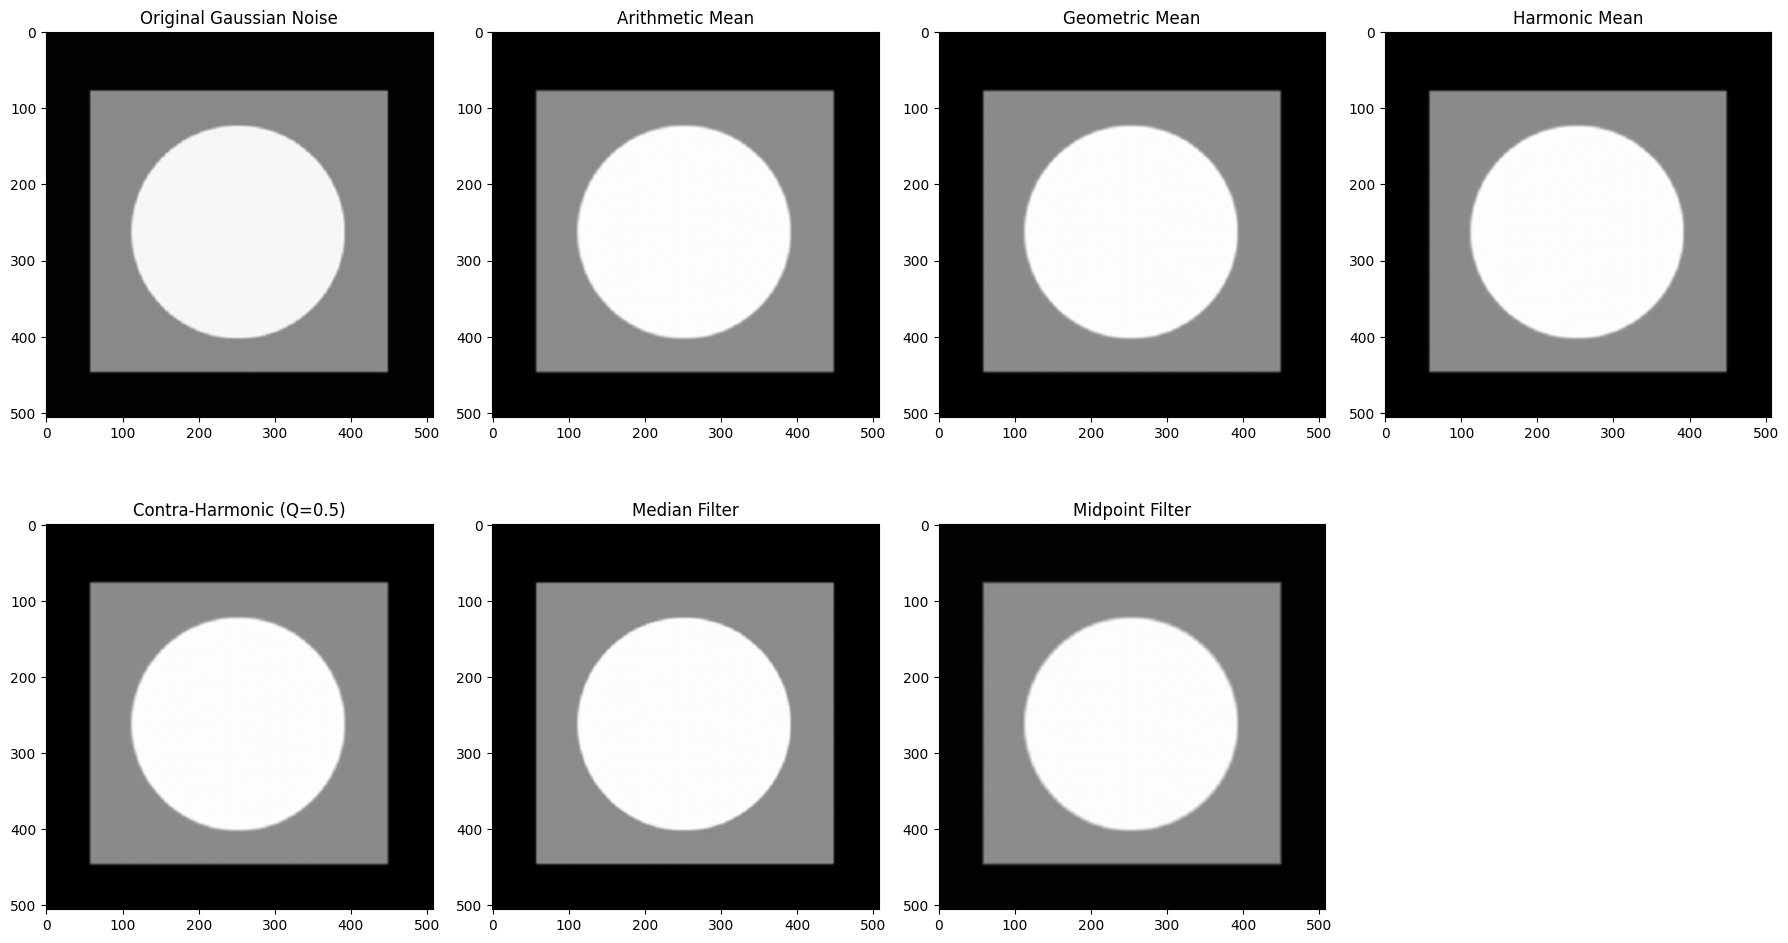

In [4]:
# Evaluate the mathematical/statistical filters on Gaussian Noise image
plt.figure(figsize=(18, 10))
plt.subplot(241), plt.imshow(img_noise, cmap='gray'), plt.title('Original Gaussian Noise')
plt.subplot(242), plt.imshow(arithmetic_mean_filter(img_noise), cmap='gray'), plt.title('Arithmetic Mean')
plt.subplot(243), plt.imshow(geometric_mean_filter(img_noise), cmap='gray'), plt.title('Geometric Mean')
plt.subplot(244), plt.imshow(harmonic_mean_filter(img_noise), cmap='gray'), plt.title('Harmonic Mean')
plt.subplot(245), plt.imshow(contra_harmonic_mean(img_noise, Q=0.5), cmap='gray'), plt.title('Contra-Harmonic (Q=0.5)')
plt.subplot(246), plt.imshow(median_filter(img_noise), cmap='gray'), plt.title('Median Filter')
plt.subplot(247), plt.imshow(midpoint_filter(img_noise), cmap='gray'), plt.title('Midpoint Filter')
plt.tight_layout()
plt.show()

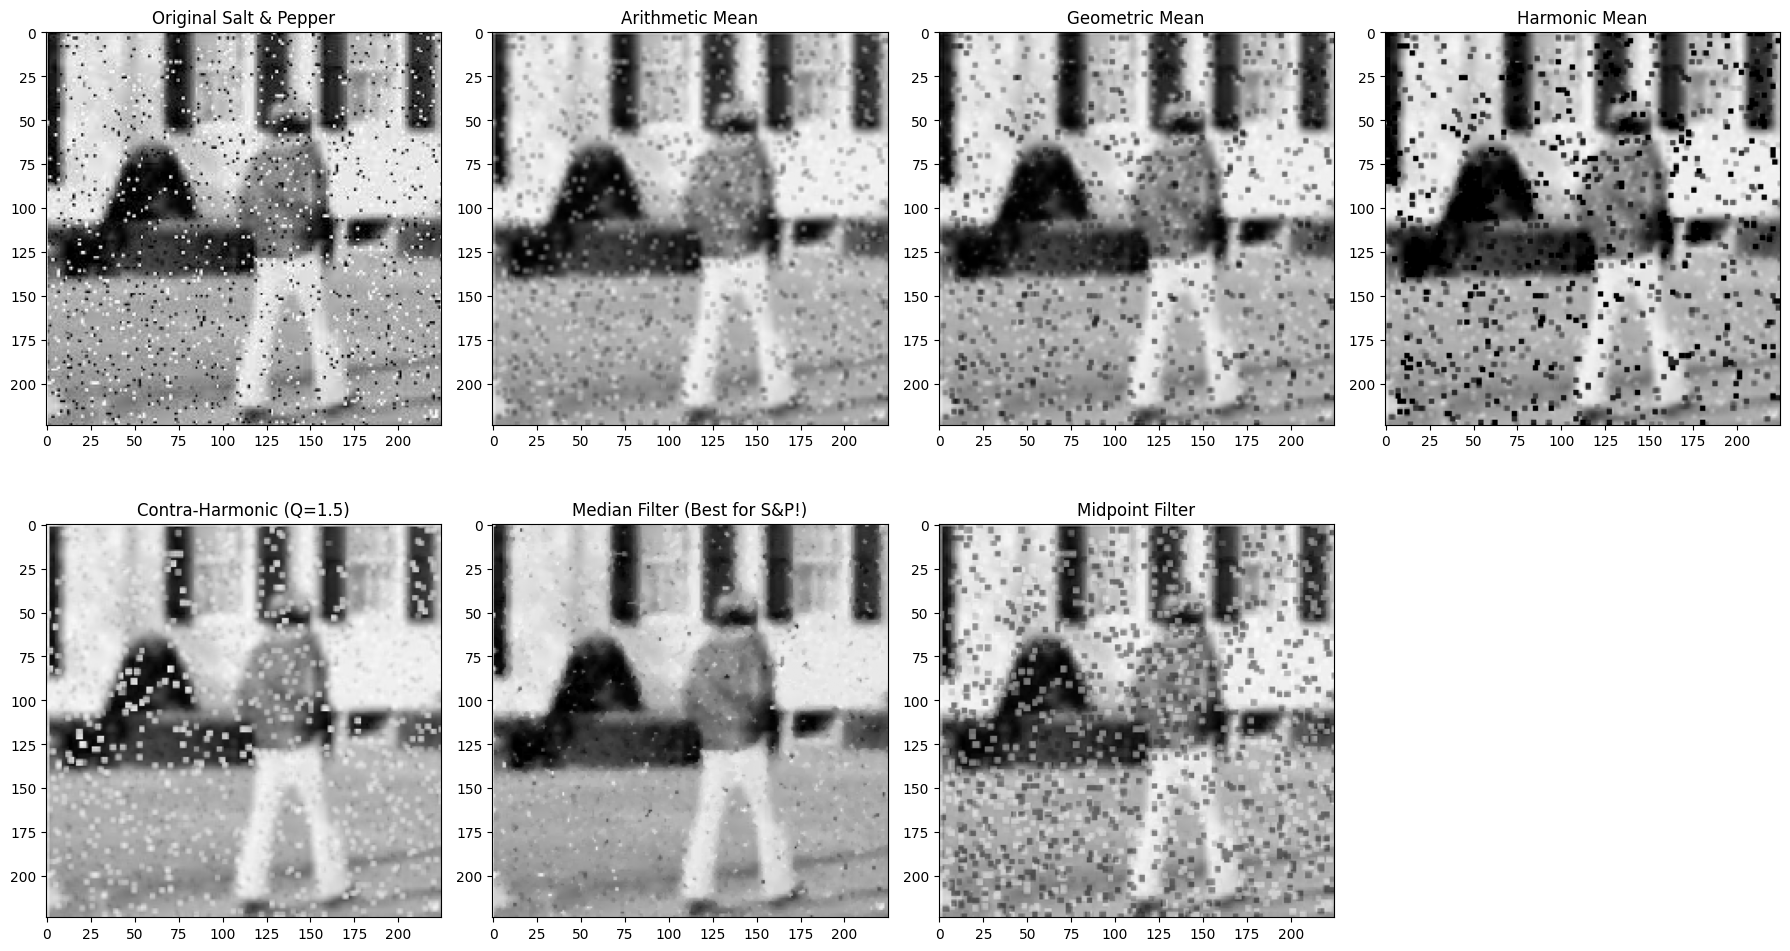

In [5]:
# Evaluate the mathematical/statistical filters on Salt & Pepper Noise image
plt.figure(figsize=(18, 10))
plt.subplot(241), plt.imshow(img_salt_pepper, cmap='gray'), plt.title('Original Salt & Pepper')
plt.subplot(242), plt.imshow(arithmetic_mean_filter(img_salt_pepper), cmap='gray'), plt.title('Arithmetic Mean')
plt.subplot(243), plt.imshow(geometric_mean_filter(img_salt_pepper), cmap='gray'), plt.title('Geometric Mean')
plt.subplot(244), plt.imshow(harmonic_mean_filter(img_salt_pepper), cmap='gray'), plt.title('Harmonic Mean')
plt.subplot(245), plt.imshow(contra_harmonic_mean(img_salt_pepper, Q=1.5), cmap='gray'), plt.title('Contra-Harmonic (Q=1.5)')
plt.subplot(246), plt.imshow(median_filter(img_salt_pepper), cmap='gray'), plt.title('Median Filter (Best for S&P!)')
plt.subplot(247), plt.imshow(midpoint_filter(img_salt_pepper), cmap='gray'), plt.title('Midpoint Filter')
plt.tight_layout()
plt.show()

##